[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MartinLam12/project-1-image-classification/blob/main/project1.ipynb)

In [1]:
# Set the random seed everywhere so results can be repeated
import random
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

# Data Loading and Preprocessing
Pixel values run from 0 to 255. We divide by 255 so they run from 0 to 1, which helps the network learn.

In [ ]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("Train:", x_train.shape, y_train.shape)
print("Test :", x_test.shape, y_test.shape)


    0/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step



       0/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step


   73728/26421880 ━━━━━━━━━━━━━━━━━━━━ 19s 1us/step


  253952/26421880 ━━━━━━━━━━━━━━━━━━━━ 10s 0us/step

...


1761280/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


3006464/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


3907584/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Train: (60000, 28, 28) (60000,)
Test : (10000, 28, 28) (10000,)


## Exploration and Visualization
Every class has 6,000 training images, so the data is balanced and accuracy is a fair measure. Shirts, pullovers and coats look alike, so we expect those to be confused with each other.

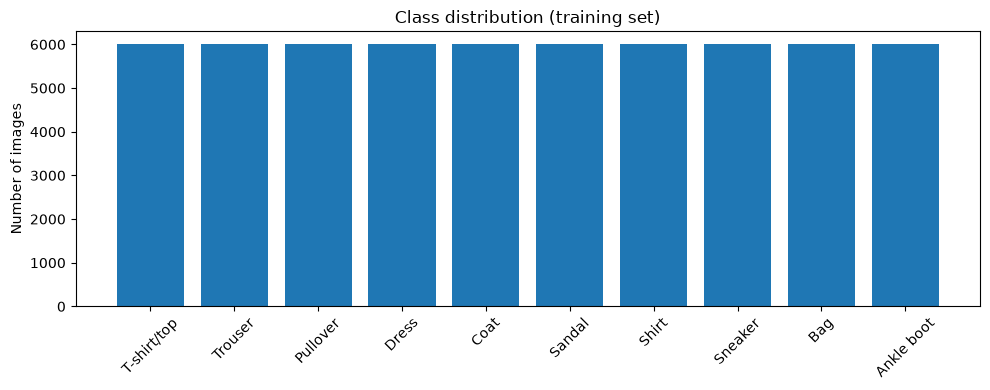

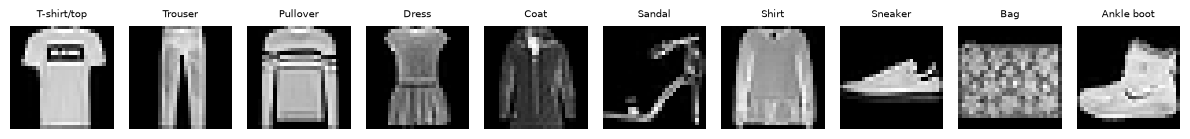

In [ ]:
# bar chart
counts = np.bincount(y_train)
plt.figure(figsize=(10, 4))
plt.bar(class_names, counts)
plt.title("Class distribution (training set)")
plt.xticks(rotation=45)
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()

# sample images
plt.figure(figsize=(12, 3))
for c in range(10):
    plt.subplot(1, 10, c + 1)
    plt.imshow(x_train[np.where(y_train == c)[0][0]], cmap="gray")
    plt.title(class_names[c], fontsize=7)
    plt.axis("off")
plt.tight_layout()
plt.show()

## Model Implementation
templates lists the size of each hidden layer, so Shallow has 2 layers and Deep has 4.

build_model makes one network. It flattens the picture, adds the hidden layers, then add the 10-neuron output layer (one score per clothing type).

In [ ]:
templates = {"Shallow": [128, 64], "Deep": [512, 256, 128, 64]}
activations = ["relu", "sigmoid", "tanh"]

def build_model(hidden_sizes, activation):
    # flatten turns the 28x28 picture into 784 numbers
    model = keras.Sequential([layers.Input(shape=(28, 28)), layers.Flatten()])
    for n in hidden_sizes:
        model.add(layers.Dense(n, activation=activation))
    model.add(layers.Dense(10, activation="softmax"))  # one score per clothing type
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

## Training and Evaluation
 Trains the model on the training pictures. It stops by itself once it stops improving. the model is then tested on 10,000 pictures it has never seen. we then display charts and scores.

Shallow network with relu


Stopped after 10 epochs


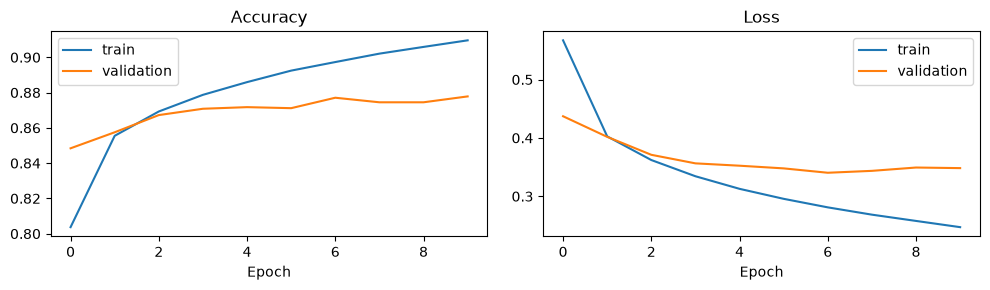

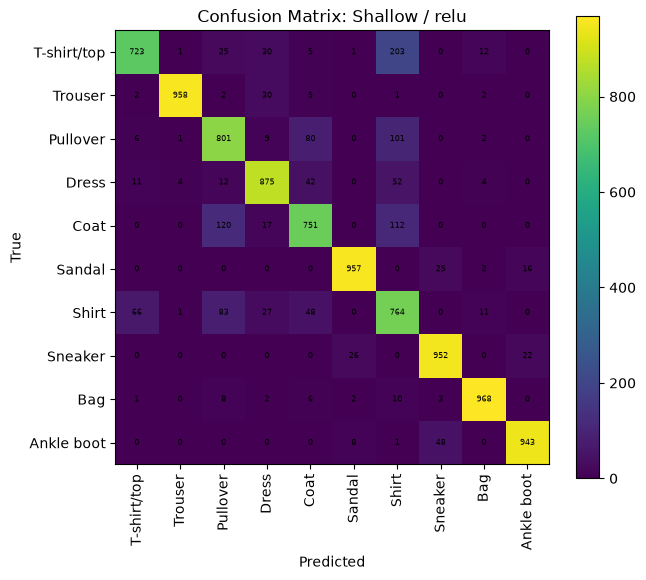

              precision    recall  f1-score   support

 T-shirt/top     0.8937    0.7230    0.7993      1000
     Trouser     0.9927    0.9580    0.9751      1000
    Pullover     0.7621    0.8010    0.7811      1000
       Dress     0.8838    0.8750    0.8794      1000
        Coat     0.8015    0.7510    0.7754      1000
      Sandal     0.9628    0.9570    0.9599      1000
       Shirt     0.6141    0.7640    0.6809      1000
     Sneaker     0.9261    0.9520    0.9389      1000
         Bag     0.9670    0.9680    0.9675      1000
  Ankle boot     0.9613    0.9430    0.9520      1000

    accuracy                         0.8692     10000
   macro avg     0.8765    0.8692    0.8710     10000
weighted avg     0.8765    0.8692    0.8710     10000

Shallow network with sigmoid


Stopped after 22 epochs


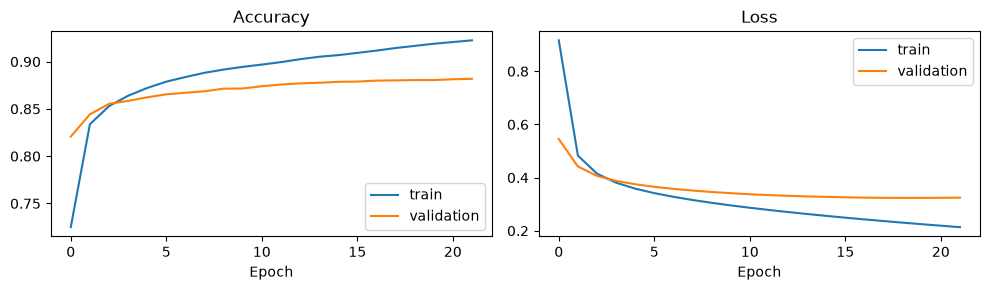

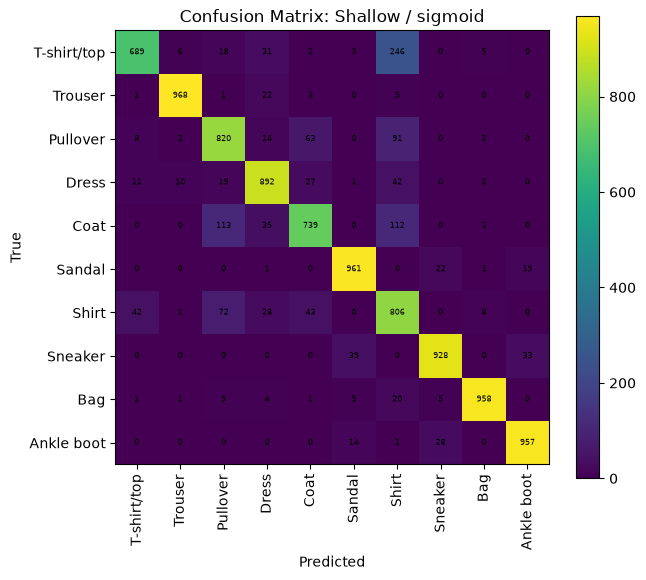

              precision    recall  f1-score   support

 T-shirt/top     0.9162    0.6890    0.7865      1000
     Trouser     0.9798    0.9680    0.9738      1000
    Pullover     0.7854    0.8200    0.8023      1000
       Dress     0.8685    0.8920    0.8801      1000
        Coat     0.8417    0.7390    0.7870      1000
      Sandal     0.9394    0.9610    0.9501      1000
       Shirt     0.6092    0.8060    0.6939      1000
     Sneaker     0.9440    0.9280    0.9360      1000
         Bag     0.9806    0.9580    0.9691      1000
  Ankle boot     0.9522    0.9570    0.9546      1000

    accuracy                         0.8718     10000
   macro avg     0.8817    0.8718    0.8734     10000
weighted avg     0.8817    0.8718    0.8734     10000

Shallow network with tanh


Stopped after 13 epochs


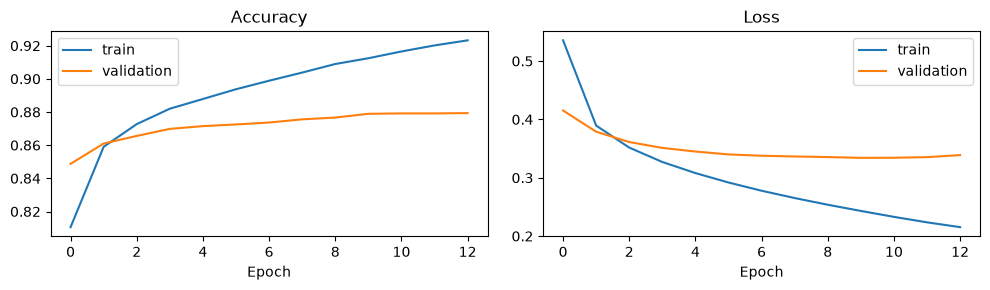

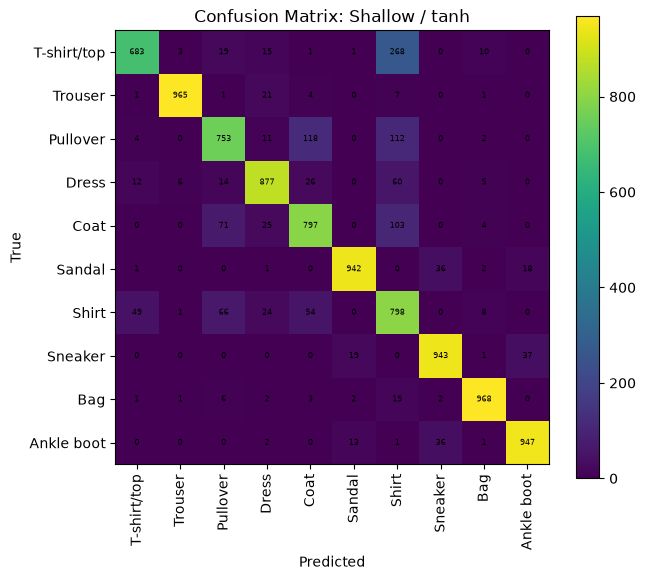

              precision    recall  f1-score   support

 T-shirt/top     0.9095    0.6830    0.7801      1000
     Trouser     0.9887    0.9650    0.9767      1000
    Pullover     0.8097    0.7530    0.7803      1000
       Dress     0.8967    0.8770    0.8868      1000
        Coat     0.7946    0.7970    0.7958      1000
      Sandal     0.9642    0.9420    0.9530      1000
       Shirt     0.5850    0.7980    0.6751      1000
     Sneaker     0.9272    0.9430    0.9351      1000
         Bag     0.9661    0.9680    0.9670      1000
  Ankle boot     0.9451    0.9470    0.9461      1000

    accuracy                         0.8673     10000
   macro avg     0.8787    0.8673    0.8696     10000
weighted avg     0.8787    0.8673    0.8696     10000

Deep network with relu


Stopped after 10 epochs


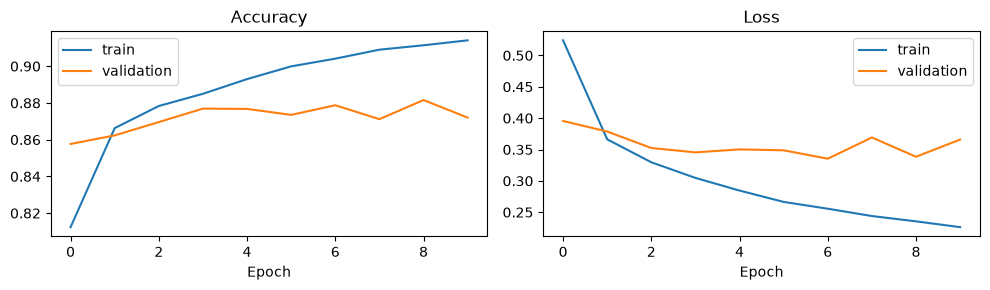

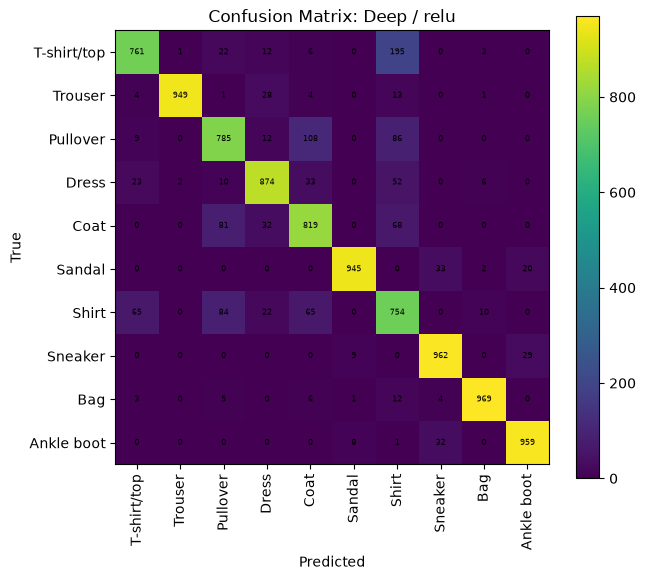

              precision    recall  f1-score   support

 T-shirt/top     0.8798    0.7610    0.8161      1000
     Trouser     0.9968    0.9490    0.9723      1000
    Pullover     0.7945    0.7850    0.7897      1000
       Dress     0.8918    0.8740    0.8828      1000
        Coat     0.7867    0.8190    0.8025      1000
      Sandal     0.9813    0.9450    0.9628      1000
       Shirt     0.6384    0.7540    0.6914      1000
     Sneaker     0.9331    0.9620    0.9473      1000
         Bag     0.9778    0.9690    0.9734      1000
  Ankle boot     0.9514    0.9590    0.9552      1000

    accuracy                         0.8777     10000
   macro avg     0.8832    0.8777    0.8794     10000
weighted avg     0.8832    0.8777    0.8794     10000

Deep network with sigmoid


Stopped after 13 epochs


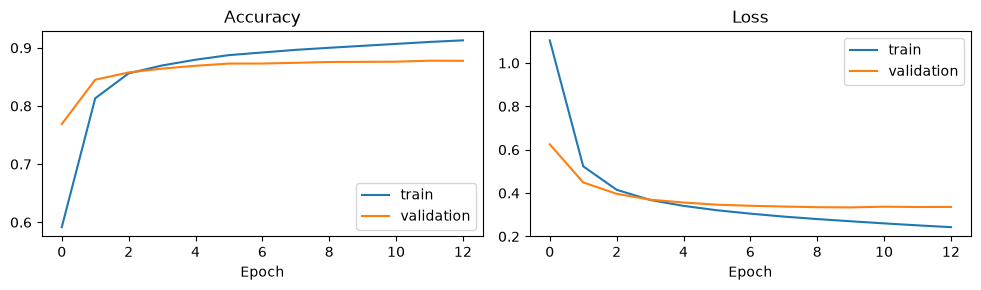

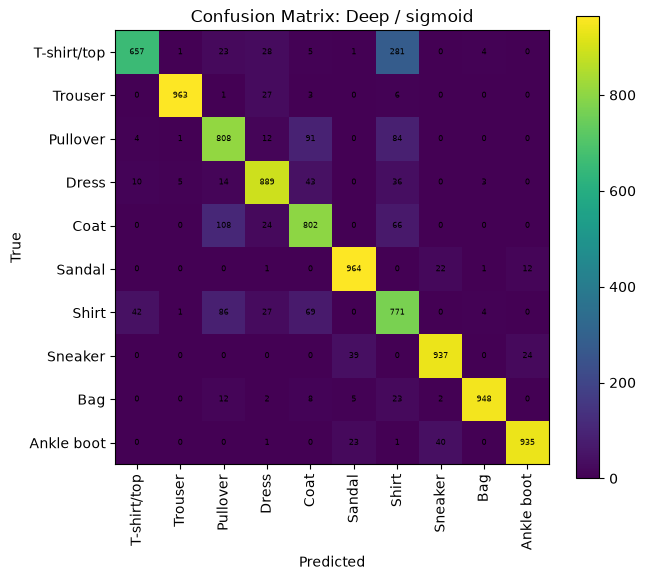

              precision    recall  f1-score   support

 T-shirt/top     0.9215    0.6570    0.7671      1000
     Trouser     0.9918    0.9630    0.9772      1000
    Pullover     0.7681    0.8080    0.7875      1000
       Dress     0.8793    0.8890    0.8841      1000
        Coat     0.7855    0.8020    0.7937      1000
      Sandal     0.9341    0.9640    0.9488      1000
       Shirt     0.6080    0.7710    0.6799      1000
     Sneaker     0.9361    0.9370    0.9365      1000
         Bag     0.9875    0.9480    0.9673      1000
  Ankle boot     0.9629    0.9350    0.9488      1000

    accuracy                         0.8674     10000
   macro avg     0.8775    0.8674    0.8691     10000
weighted avg     0.8775    0.8674    0.8691     10000

Deep network with tanh


Stopped after 10 epochs


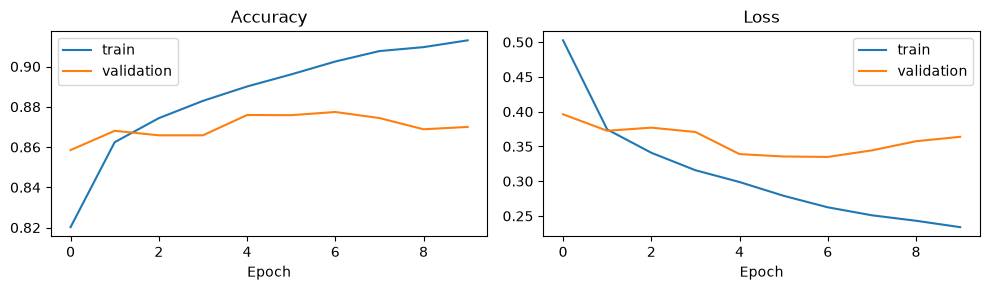

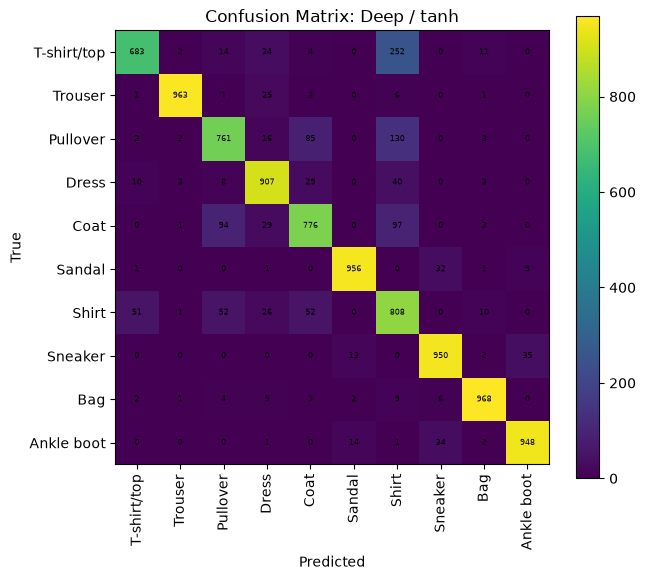

              precision    recall  f1-score   support

 T-shirt/top     0.9095    0.6830    0.7801      1000
     Trouser     0.9897    0.9630    0.9762      1000
    Pullover     0.8148    0.7610    0.7870      1000
       Dress     0.8688    0.9070    0.8875      1000
        Coat     0.8151    0.7760    0.7951      1000
      Sandal     0.9706    0.9560    0.9632      1000
       Shirt     0.6016    0.8080    0.6897      1000
     Sneaker     0.9295    0.9500    0.9397      1000
         Bag     0.9641    0.9680    0.9661      1000
  Ankle boot     0.9556    0.9480    0.9518      1000

    accuracy                         0.8720     10000
   macro avg     0.8819    0.8720    0.8736     10000
weighted avg     0.8819    0.8720    0.8736     10000



In [ ]:
results = []  # one row per model for the final table

for name, sizes in templates.items():
    for act in activations:
        print("=" * 60)
        print(f"{name} network with {act}")
        model = build_model(sizes, act)

        # stop when validation loss stops improving for 3 epochs
        stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                             restore_best_weights=True)
        history = model.fit(x_train, y_train, validation_split=0.2,
                            epochs=50, batch_size=128, callbacks=[stop], verbose=0)
        print("Stopped after", len(history.history["loss"]), "epochs")

        # final score on the test set (pictures the model never saw)
        test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
        results.append((name, act, test_acc, test_loss))

        # accuracy and loss curves
        plt.figure(figsize=(10, 3))
        plt.subplot(1, 2, 1)
        plt.plot(history.history["accuracy"], label="train")
        plt.plot(history.history["val_accuracy"], label="validation")
        plt.title("Accuracy"); plt.xlabel("Epoch"); plt.legend()
        plt.subplot(1, 2, 2)
        plt.plot(history.history["loss"], label="train")
        plt.plot(history.history["val_loss"], label="validation")
        plt.title("Loss"); plt.xlabel("Epoch"); plt.legend()
        plt.tight_layout()
        plt.show()

        # confusion matrix and classification report on the test set
        y_pred = np.argmax(model.predict(x_test, verbose=0), axis=1)
        cm = confusion_matrix(y_test, y_pred)
        plt.figure(figsize=(7, 6))
        plt.imshow(cm)
        plt.title(f"Confusion Matrix: {name} / {act}")
        plt.xlabel("Predicted"); plt.ylabel("True")
        plt.xticks(range(10), class_names, rotation=90)
        plt.yticks(range(10), class_names)
        plt.colorbar()
        for i in range(10):
            for j in range(10):
                plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=6)
        plt.show()
        print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

## Results Table

In [6]:
# Side-by-side comparison of all six models (test set)
print(f"{'Template':<10}{'Activation':<12}{'Test Accuracy':<15}{'Test Loss':<10}")
for name, act, acc, loss in results:
    print(f"{name:<10}{act:<12}{acc:<15.4f}{loss:<10.4f}")

Template  Activation  Test Accuracy  Test Loss 
Shallow   relu        0.8692         0.3604    
Shallow   sigmoid     0.8718         0.3525    
Shallow   tanh        0.8673         0.3578    
Deep      relu        0.8777         0.3577    
Deep      sigmoid     0.8674         0.3611    
Deep      tanh        0.8720         0.3540    


## Reflection

**1. Which architecture template with a specific activation function performed better? Why?**
The Deep network with ReLU scored highest. ReLU is simple and does not squash its values, so the extra layers in the deep network can pass learning signals back easily. Sigmoid and Tanh flatten large values, which makes deeper networks harder to train, and the deep Sigmoid model was the weakest of the deep models.

**2. What did the evaluation metrics tell you that accuracy did not?**
Accuracy hides which items the model gets wrong. The classification report and confusion matrix show that Shirt is the hardest class, while Trouser, Bag and Sandal are near 0.95 or higher. Shirts are mostly confused with T-shirts, pullovers and coats. A single accuracy number would not reveal that these look-alike tops are where nearly all the mistakes happen.

**3. How would you improve your models?**
Use a convolutional neural network (which looks at shapes in the image instead of a flat list of pixels), add dropout or batch normalization to reduce overfitting, try different layer sizes and learning rates, and augment the data (small flips and shifts).

**4. What are some potential ethical risks or limitations of using deep learning for image classification tasks like this one?**
This dataset is clean, centered, single item product photos, so a model trained on it may fail on real-world photos (bad lighting, people wearing the clothes, etc). If a similar system were used for store inventory, its errors on certain categories could mislead shoppers or sellers.